In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
from patsy import build_design_matrices
from scipy.special import expit
from scipy.stats import spearmanr, kendalltau
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix
)

out_dir = "xai_outputs_hba1c"
os.makedirs(out_dir, exist_ok=True)

data_path = "../../data/hba1c/diabetic_data_initial.csv"
map_path = "../../data/hba1c/id_mapping.csv"

df = pd.read_csv(data_path, keep_default_na=False)
idmap_raw = pd.read_csv(map_path, keep_default_na=False)


In [5]:
# -----------------------------
# Parse ID mapping file
# -----------------------------
idmap_raw.columns = ["id", "description"]
idmap_raw["id"] = idmap_raw["id"].astype(str).str.strip()
idmap_raw["description"] = idmap_raw["description"].astype(str).str.strip()

def parse_id_mapping(idmap_raw):
    sections = {}
    current_section = None
    current_rows = []

    for _, row in idmap_raw.iterrows():
        left = str(row["id"]).strip()
        right = str(row["description"]).strip()

        if left in ["nan", "ID mappings for the diabetes dataset"]:
            continue
        if right in ["nan", "? - always means a missing value"]:
            continue

        if left in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
            if current_section is not None and current_rows:
                sections[current_section] = pd.DataFrame(current_rows, columns=["id", "description"])
            current_section = left
            current_rows = []
            continue

        if left == "description" or right == "description":
            continue

        try:
            key = int(float(left))
            current_rows.append((key, right))
        except Exception:
            pass

    if current_section is not None and current_rows:
        sections[current_section] = pd.DataFrame(current_rows, columns=["id", "description"])

    return sections

sections = parse_id_mapping(idmap_raw)

admission_type_map = dict(zip(sections["admission_type_id"]["id"], sections["admission_type_id"]["description"]))
discharge_map = dict(zip(sections["discharge_disposition_id"]["id"], sections["discharge_disposition_id"]["description"]))
admission_source_map = dict(zip(sections["admission_source_id"]["id"], sections["admission_source_id"]["description"]))


In [6]:
# -----------------------------
# Main preprocessing
# -----------------------------
df2 = df.copy()

df2["readmitted_bin"] = (df2["readmitted"] == "<30").astype(int)
df2 = df2.drop(columns=["weight", "payer_code"], errors="ignore")

df2["medical_specialty"] = df2["medical_specialty"].replace("?", np.nan).fillna("missing")
df2["race"] = df2["race"].replace("?", np.nan).fillna("Missing")

df2["discharge_desc"] = df2["discharge_disposition_id"].map(discharge_map)
df2["admission_type_desc"] = df2["admission_type_id"].map(admission_type_map)
df2["admission_source_desc"] = df2["admission_source_id"].map(admission_source_map)

df2 = (
    df2.sort_values(["patient_nbr", "encounter_id"])
       .drop_duplicates(subset="patient_nbr", keep="first")
       .copy()
)

df2 = df2[df2["gender"].isin(["Female", "Male"])].copy()

death_hospice_ids = [11, 13, 14, 19, 20, 21]
df2 = df2[~df2["discharge_disposition_id"].isin(death_hospice_ids)].copy()

In [7]:
# -----------------------------
# Derived variables
# -----------------------------
def make_hba1c_group(row):
    a1c = str(row["A1Cresult"]).strip()
    change = str(row["change"]).strip()

    if a1c == "None":
        return "No test was performed"
    elif a1c in ["Norm", ">7"]:
        return "Normal result of the test"
    elif a1c == ">8" and change == "No":
        return "Result was high but the diabetic medication was not changed"
    elif a1c == ">8" and change == "Ch":
        return "Result was high and the diabetic medication was changed"
    else:
        return np.nan

df2["hba1c_group"] = df2.apply(make_hba1c_group, axis=1)

df2["discharge_group"] = np.where(
    df2["discharge_disposition_id"] == 1,
    "Discharged to home",
    "Otherwise"
)

def map_admission_source(x):
    if x == 7:
        return "Admitted from emergency room"
    elif x in [1, 2, 3]:
        return "Admitted because of physician/clinic referral"
    else:
        return "Otherwise"

df2["admission_source_group"] = df2["admission_source_id"].apply(map_admission_source)

def map_specialty(x):
    if x == "InternalMedicine":
        return "Internal Medicine"
    elif x == "Cardiology":
        return "Cardiology"
    elif "Surgery" in str(x):
        return "Surgery"
    elif x in ["Family/GeneralPractice", "FamilyPractice"]:
        return "Family/general practice"
    elif x == "missing":
        return "Missing or unknown"
    else:
        return "Other"

df2["specialty_group"] = df2["medical_specialty"].apply(map_specialty)

def map_race(x):
    if x == "AfricanAmerican":
        return "African American"
    elif x == "Caucasian":
        return "Caucasian"
    elif x == "Missing":
        return "Missing"
    else:
        return "Other"

df2["race_group"] = df2["race"].apply(map_race)

def age_midpoint(age_str):
    nums = [int(x) for x in str(age_str).replace("[", "").replace(")", "").split("-") if x.isdigit()]
    if len(nums) == 2:
        return (nums[0] + nums[1]) / 2
    return np.nan

df2["age_mid"] = df2["age"].apply(age_midpoint)

def map_age_group3(x):
    if pd.isna(x):
        return np.nan
    elif x <= 30:
        return "30 years old or younger"
    elif x <= 60:
        return "30-60 years old"
    else:
        return "Older than 60"

df2["age_group3"] = df2["age_mid"].apply(map_age_group3)

def group_primary_diag(code):
    code = str(code).strip()

    if code.startswith("V") or code.startswith("E"):
        return "Other"
    if code.startswith("250"):
        return "Diabetes"

    m = re.match(r"^(\d+)", code)
    if not m:
        return "Other"

    num = int(m.group(1))

    if 390 <= num <= 459 or num == 785:
        return "Circulatory"
    elif 460 <= num <= 519 or num == 786:
        return "Respiratory"
    elif 520 <= num <= 579 or num == 787:
        return "Digestive"
    elif 800 <= num <= 999:
        return "Injury"
    elif 710 <= num <= 739:
        return "Musculoskeletal"
    elif 580 <= num <= 629 or num == 788:
        return "Genitourinary"
    elif 140 <= num <= 239:
        return "Neoplasms"
    else:
        return "Other"

df2["primary_diag_group"] = df2["diag_1"].apply(group_primary_diag)

analysis_df = df2[[
    "readmitted_bin",
    "hba1c_group",
    "gender",
    "discharge_group",
    "admission_source_group",
    "specialty_group",
    "primary_diag_group",
    "race_group",
    "age_group3",
    "age_mid",
    "time_in_hospital"
]].dropna().copy()

analysis_df["discharge_group"] = pd.Categorical(
    analysis_df["discharge_group"],
    categories=["Discharged to home", "Otherwise"]
)

analysis_df["race_group"] = pd.Categorical(
    analysis_df["race_group"],
    categories=["African American", "Caucasian", "Missing", "Other"]
)

analysis_df["admission_source_group"] = pd.Categorical(
    analysis_df["admission_source_group"],
    categories=[
        "Admitted from emergency room",
        "Admitted because of physician/clinic referral",
        "Otherwise"
    ]
)

analysis_df["specialty_group"] = pd.Categorical(
    analysis_df["specialty_group"],
    categories=[
        "Cardiology",
        "Family/general practice",
        "Internal Medicine",
        "Missing or unknown",
        "Other",
        "Surgery"
    ]
)

analysis_df["age_group3"] = pd.Categorical(
    analysis_df["age_group3"],
    categories=[
        "30-60 years old",
        "Older than 60",
        "30 years old or younger"
    ]
)

analysis_df["primary_diag_group"] = pd.Categorical(
    analysis_df["primary_diag_group"],
    categories=[
        "Diabetes",
        "Circulatory",
        "Digestive",
        "Genitourinary",
        "Injury",
        "Musculoskeletal",
        "Neoplasms",
        "Other",
        "Respiratory"
    ]
)

analysis_df["hba1c_group"] = pd.Categorical(
    analysis_df["hba1c_group"],
    categories=[
        "No test was performed",
        "Normal result of the test",
        "Result was high and the diabetic medication was changed",
        "Result was high but the diabetic medication was not changed"
    ],
    ordered=True
)

for c in [
    "hba1c_group", "gender", "discharge_group", "admission_source_group",
    "specialty_group", "primary_diag_group", "race_group", "age_group3"
]:
    analysis_df[c] = analysis_df[c].astype("category")

final_model = smf.logit(
    "readmitted_bin ~ gender + race_group + admission_source_group + "
    "discharge_group + specialty_group + primary_diag_group + "
    "age_group3 + time_in_hospital + hba1c_group + "
    "discharge_group:race_group + "
    "discharge_group:specialty_group + "
    "discharge_group:primary_diag_group + "
    "discharge_group:time_in_hospital + "
    "specialty_group:time_in_hospital + "
    "specialty_group:age_group3 + "
    "primary_diag_group:time_in_hospital + "
    "primary_diag_group:hba1c_group",
    data=analysis_df
).fit(maxiter=200)

print("analysis_df shape:", analysis_df.shape)
print(final_model.summary())

Optimization terminated successfully.
         Current function value: 0.294692
         Iterations 8
analysis_df shape: (69970, 11)
                           Logit Regression Results                           
Dep. Variable:         readmitted_bin   No. Observations:                69970
Model:                          Logit   Df Residuals:                    69879
Method:                           MLE   Df Model:                           90
Date:                Tue, 14 Apr 2026   Pseudo R-squ.:                 0.02377
Time:                        18:37:50   Log-Likelihood:                -20620.
converged:                       True   LL-Null:                       -21122.
Covariance Type:            nonrobust   LLR p-value:                2.685e-154
                                                                                                                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from patsy import build_design_matrices
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix
)
from scipy.special import expit
from scipy.stats import spearmanr, kendalltau

out_dir = "xai_outputs_hba1c"
os.makedirs(out_dir, exist_ok=True)

# -----------------------------
# 1. Build design matrix from final statsmodels model
# -----------------------------
design_info = final_model.model.data.design_info

X_design = build_design_matrices(
    [design_info],
    analysis_df,
    return_type="dataframe"
)[0]

y_true = analysis_df["readmitted_bin"].copy()
y_prob = final_model.predict(analysis_df)

# pick a descriptive threshold using Youden J
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

y_pred = (y_prob >= best_threshold).astype(int)

print("Final XAI model: statsmodels logistic regression with interactions")
print("AUC       :", round(roc_auc_score(y_true, y_prob), 4))
print("Threshold :", round(best_threshold, 4))
print("Accuracy  :", round(accuracy_score(y_true, y_pred), 4))
print("Precision :", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall    :", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1        :", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))


Final XAI model: statsmodels logistic regression with interactions
AUC       : 0.6189
Threshold : 0.0842
Accuracy  : 0.546
Precision : 0.1193
Recall    : 0.6365
F1        : 0.201

Confusion matrix:
[[34207 29486]
 [ 2282  3995]]


In [9]:
# -----------------------------
# 2. Exact additive contributions
# -----------------------------
params = final_model.params.reindex(X_design.columns)

# baseline at mean design vector
mean_design = X_design.mean(axis=0)
baseline_logit = float((mean_design * params).sum())

# centered contribution matrix
centered_contrib = (X_design - mean_design).mul(params, axis=1)

# exact term-level importance
term_importance = (
    centered_contrib.drop(columns=["Intercept"], errors="ignore")
    .abs()
    .mean(axis=0)
    .sort_values(ascending=False)
    .rename("MeanAbsContribution")
    .reset_index()
    .rename(columns={"index": "Term"})
)

print("\nExact term contribution importance")
print(term_importance.head(20).round(4))



Exact term contribution importance
                                                 Term  MeanAbsContribution
0                                    time_in_hospital               0.2948
1               specialty_group[T.Missing or unknown]               0.2106
2                        discharge_group[T.Otherwise]               0.1340
3   specialty_group[T.Missing or unknown]:time_in_...               0.1310
4                         age_group3[T.Older than 60]               0.1200
5                specialty_group[T.Internal Medicine]               0.1038
6               age_group3[T.30 years old or younger]               0.0935
7                            specialty_group[T.Other]               0.0875
8               primary_diag_group[T.Musculoskeletal]               0.0795
9        primary_diag_group[T.Other]:time_in_hospital               0.0756
10                  primary_diag_group[T.Respiratory]               0.0752
11  discharge_group[T.Otherwise]:specialty_group[T...           

C:\Users\catia\AppData\Local\Temp\ipykernel_17460\3926034874.py:21: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  grouped_abs.groupby(group_map, axis=1).sum()



Grouped contribution importance
                           PredictorGroup  MeanAbsContribution
0                         specialty_group               0.4983
1      specialty_group × time_in_hospital               0.3220
2                        time_in_hospital               0.2948
3                      primary_diag_group               0.2536
4   primary_diag_group × time_in_hospital               0.2332
5                              age_group3               0.2136
6            specialty_group × age_group3               0.1885
7       discharge_group × specialty_group               0.1802
8                         discharge_group               0.1340
9    discharge_group × primary_diag_group               0.0970
10       primary_diag_group × hba1c_group               0.0914
11                            hba1c_group               0.0771
12     discharge_group × time_in_hospital               0.0706
13                             race_group               0.0471
14                 adm

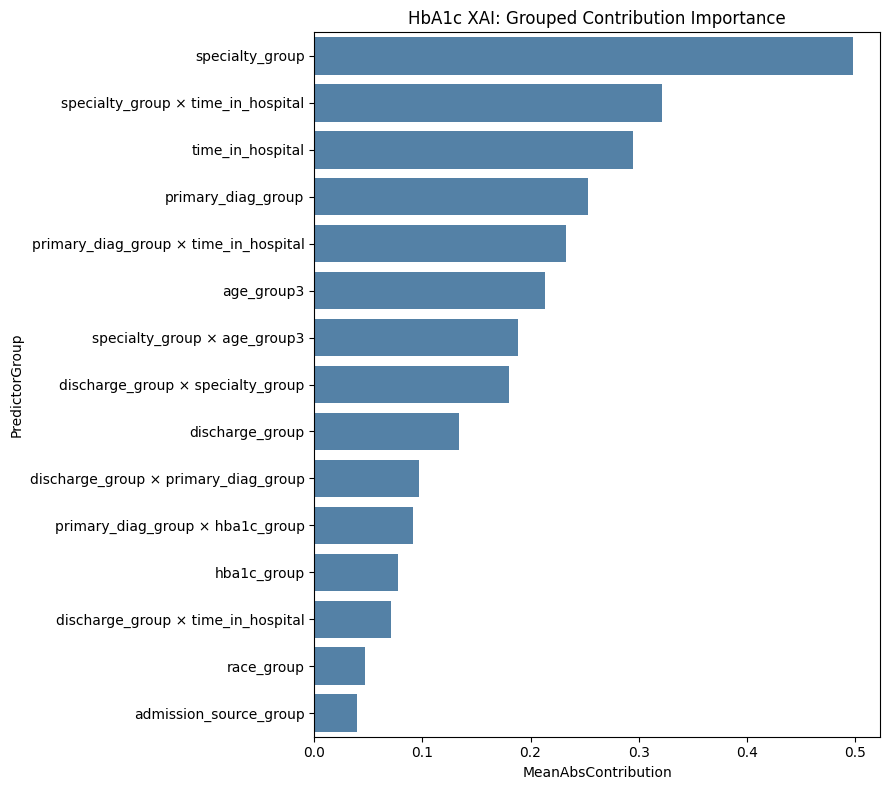

In [10]:
# -----------------------------
# 3. Group terms into predictor families
# -----------------------------
def base_from_term(term):
    if term == "Intercept":
        return "Intercept"
    parts = term.split(":")
    cleaned = []
    for p in parts:
        cleaned.append(p.split("[")[0])
    return " × ".join(cleaned)

group_map = {
    col: base_from_term(col)
    for col in centered_contrib.columns
    if col != "Intercept"
}

grouped_abs = centered_contrib.drop(columns=["Intercept"], errors="ignore").abs()
group_importance = (
    grouped_abs.groupby(group_map, axis=1).sum()
    .mean(axis=0)
    .sort_values(ascending=False)
    .rename("MeanAbsContribution")
    .reset_index()
    .rename(columns={"index": "PredictorGroup"})
)

print("\nGrouped contribution importance")
print(group_importance.round(4))

plt.figure(figsize=(9, 8))
sns.barplot(data=group_importance.head(15), x="MeanAbsContribution", y="PredictorGroup", color="steelblue")
plt.title("HbA1c XAI: Grouped Contribution Importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "hba1c_grouped_contribution_importance.png"), dpi=300)
plt.show()



Permutation importance
                  Feature  PermutationMean  PermutationStd
2         discharge_group           0.0602          0.0024
5      primary_diag_group           0.0190          0.0017
9        time_in_hospital           0.0148          0.0012
4         specialty_group           0.0109          0.0009
7              age_group3           0.0085          0.0009
0             hba1c_group           0.0058          0.0006
6              race_group           0.0022          0.0004
3  admission_source_group           0.0012          0.0003
1                  gender           0.0001          0.0002
8                 age_mid           0.0000          0.0000


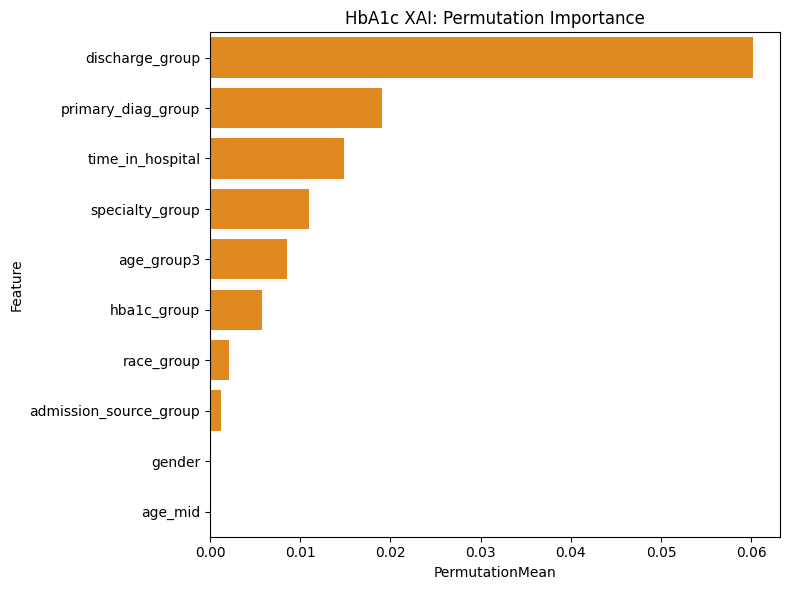

In [12]:
# -----------------------------
# 4. Permutation importance on original predictors
# -----------------------------
rng = np.random.default_rng(42)

predictor_cols = [
    c for c in analysis_df.columns
    if c != "readmitted_bin"
]

base_auc = roc_auc_score(y_true, y_prob)

perm_rows = []

for col in predictor_cols:
    drops = []

    for _ in range(10):
        df_perm = analysis_df.copy()
        df_perm[col] = rng.permutation(df_perm[col].values)

        perm_prob = final_model.predict(df_perm)
        perm_auc = roc_auc_score(y_true, perm_prob)

        drops.append(base_auc - perm_auc)

    perm_rows.append({
        "Feature": col,
        "PermutationMean": np.mean(drops),
        "PermutationStd": np.std(drops)
    })

perm_df = pd.DataFrame(perm_rows).sort_values("PermutationMean", ascending=False)

print("\nPermutation importance")
print(perm_df.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=perm_df, x="PermutationMean", y="Feature", color="darkorange")
plt.title("HbA1c XAI: Permutation Importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "hba1c_permutation_importance.png"), dpi=300)
plt.show()



Grouped contribution vs permutation rank comparison
           PredictorGroup  MeanAbsContribution  GroupRank  \
0         specialty_group               0.4983          1   
1        time_in_hospital               0.2948          3   
2      primary_diag_group               0.2536          4   
3              age_group3               0.2136          6   
4         discharge_group               0.1340          9   
5             hba1c_group               0.0771         12   
6              race_group               0.0471         14   
7  admission_source_group               0.0393         15   
8                  gender               0.0141         17   

                  Feature  PermutationMean  PermutationStd  PermutationRank  
0         specialty_group           0.0109          0.0009                4  
1        time_in_hospital           0.0148          0.0012                3  
2      primary_diag_group           0.0190          0.0017                2  
3              age_group

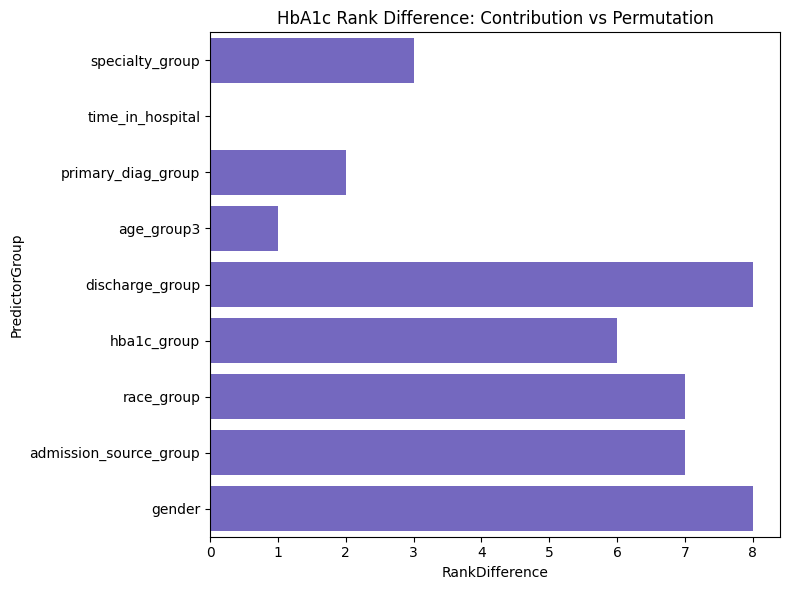

In [13]:
# -----------------------------
# 5. Rank agreement: grouped contributions vs permutation
# -----------------------------
group_rank = group_importance.copy().reset_index(drop=True)
group_rank["GroupRank"] = np.arange(1, len(group_rank) + 1)

# keep only comparable original features, not interaction-only groups
main_group_rank = group_rank[
    ~group_rank["PredictorGroup"].str.contains("×", regex=False)
].copy()

perm_rank = perm_df.copy().reset_index(drop=True)
perm_rank["PermutationRank"] = np.arange(1, len(perm_rank) + 1)

rank_compare = main_group_rank.merge(
    perm_rank,
    left_on="PredictorGroup",
    right_on="Feature",
    how="inner"
)

rho, rho_p = spearmanr(rank_compare["GroupRank"], rank_compare["PermutationRank"])
tau, tau_p = kendalltau(rank_compare["GroupRank"], rank_compare["PermutationRank"])

print("\nGrouped contribution vs permutation rank comparison")
print(rank_compare.round(4))
print(f"\nSpearman rank correlation: {rho:.4f} (p={rho_p:.4f})")
print(f"Kendall tau: {tau:.4f} (p={tau_p:.4f})")

rank_compare["RankDifference"] = (
    rank_compare["GroupRank"] - rank_compare["PermutationRank"]
).abs()

plt.figure(figsize=(8, 6))
sns.barplot(
    data=rank_compare.sort_values("GroupRank"),
    x="RankDifference",
    y="PredictorGroup",
    color="slateblue"
)
plt.title("HbA1c Rank Difference: Contribution vs Permutation")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "hba1c_rank_difference.png"), dpi=300)
plt.show()


In [14]:
# -----------------------------
# 6. Representative cases
# -----------------------------
case_df = analysis_df.copy()
case_df["y_true"] = y_true.values
case_df["y_prob"] = y_prob
case_df["y_pred"] = y_pred
case_df["dist_to_thr"] = np.abs(case_df["y_prob"] - best_threshold)

tp = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

tn = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

fp = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

fn = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

borderline = case_df.sort_values("dist_to_thr").head(1).copy()

tp["CaseType"] = "TP"
tn["CaseType"] = "TN"
fp["CaseType"] = "FP"
fn["CaseType"] = "FN"
borderline["CaseType"] = "Borderline"

rep_cases = pd.concat([tp, tn, fp, fn, borderline]).drop_duplicates()

print("\nRepresentative cases")
print(rep_cases[[
    "CaseType", "readmitted_bin", "y_pred", "y_prob",
    "hba1c_group", "primary_diag_group", "discharge_group",
    "specialty_group", "age_group3", "time_in_hospital"
]].round(4))

rep_cases.to_csv(os.path.join(out_dir, "hba1c_representative_cases.csv"), index=True)



Representative cases
         CaseType  readmitted_bin  y_pred  y_prob  \
71214          TP               1       1  0.3165   
20924          TN               0       0  0.0095   
98382          FP               0       1  0.3528   
1313           FN               1       0  0.0208   
85617  Borderline               1       1  0.0842   

                                             hba1c_group primary_diag_group  \
71214                              No test was performed        Circulatory   
20924  Result was high and the diabetic medication wa...             Injury   
98382                          Normal result of the test      Genitourinary   
1313                           Normal result of the test        Respiratory   
85617                              No test was performed        Circulatory   

          discharge_group     specialty_group               age_group3  \
71214  Discharged to home          Cardiology  30 years old or younger   
20924  Discharged to home           


Local explanation for case 71214
CaseType                TP
readmitted_bin           1
y_pred                   1
y_prob            0.316508
Name: 71214, dtype: object


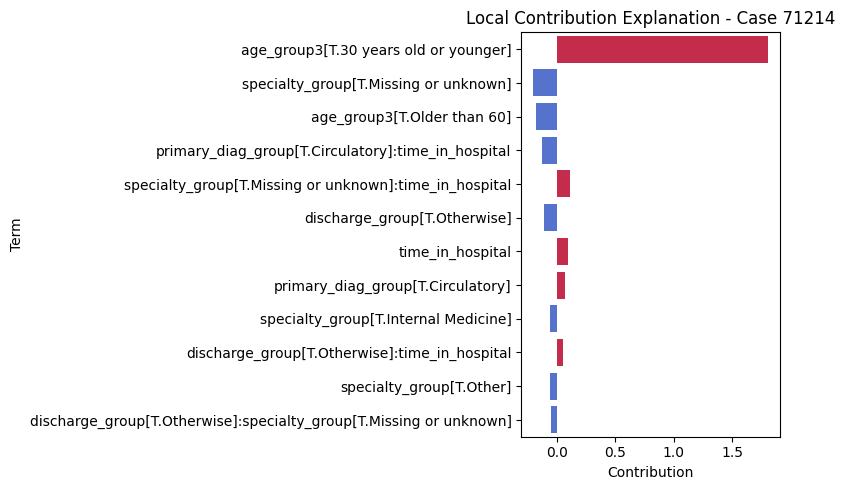


Local explanation for case 20924
CaseType                TN
readmitted_bin           0
y_pred                   0
y_prob            0.009532
Name: 20924, dtype: object


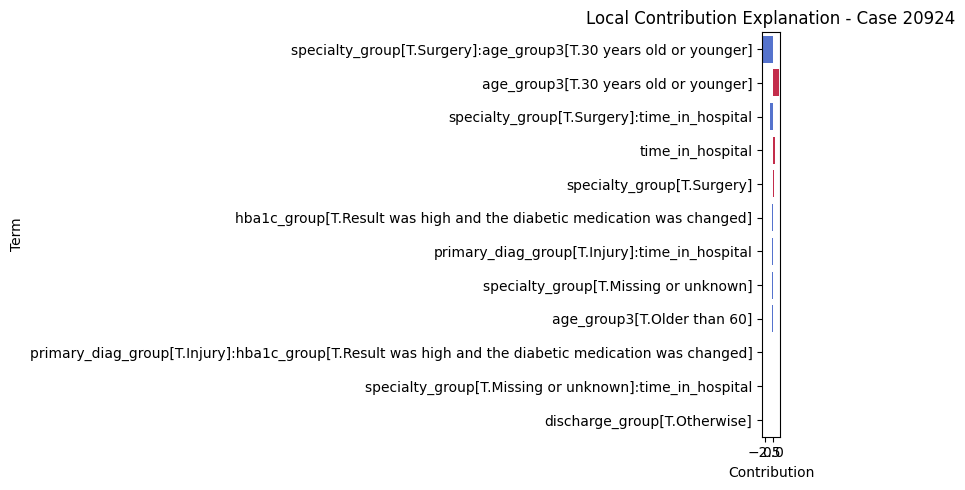


Local explanation for case 98382
CaseType                FP
readmitted_bin           0
y_pred                   1
y_prob            0.352826
Name: 98382, dtype: object


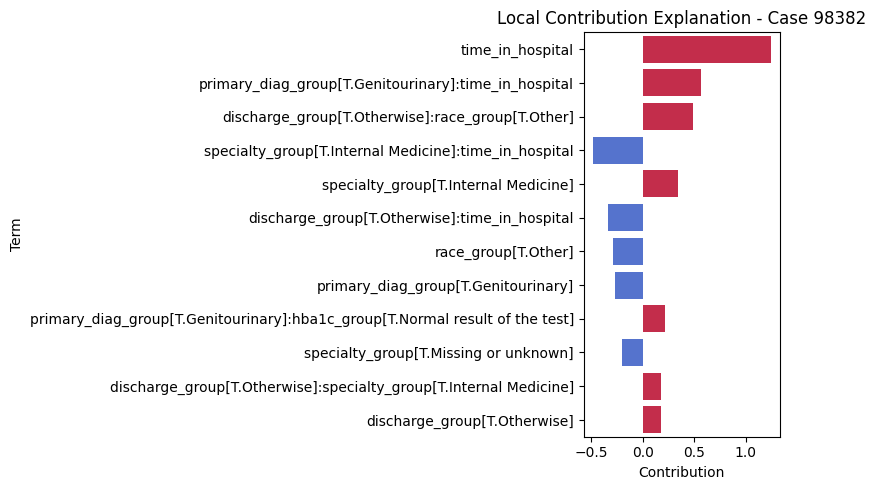


Local explanation for case 1313
CaseType                FN
readmitted_bin           1
y_pred                   0
y_prob            0.020809
Name: 1313, dtype: object


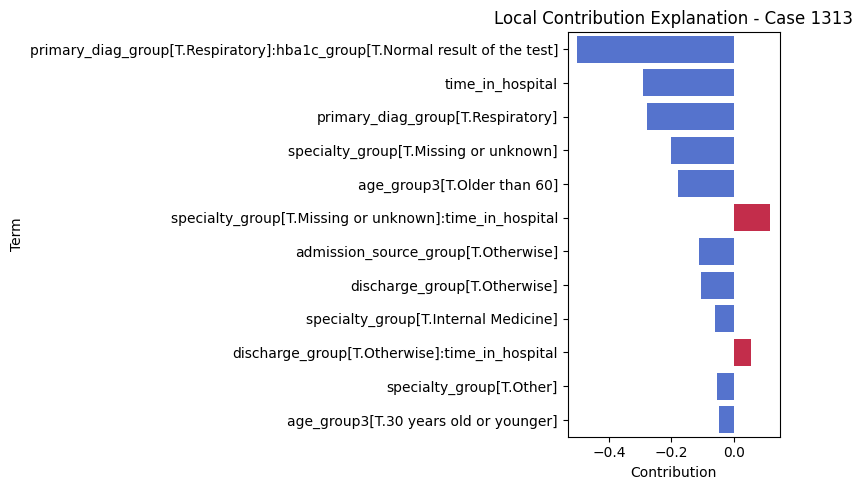


Local explanation for case 85617
CaseType          Borderline
readmitted_bin             1
y_pred                     1
y_prob              0.084229
Name: 85617, dtype: object


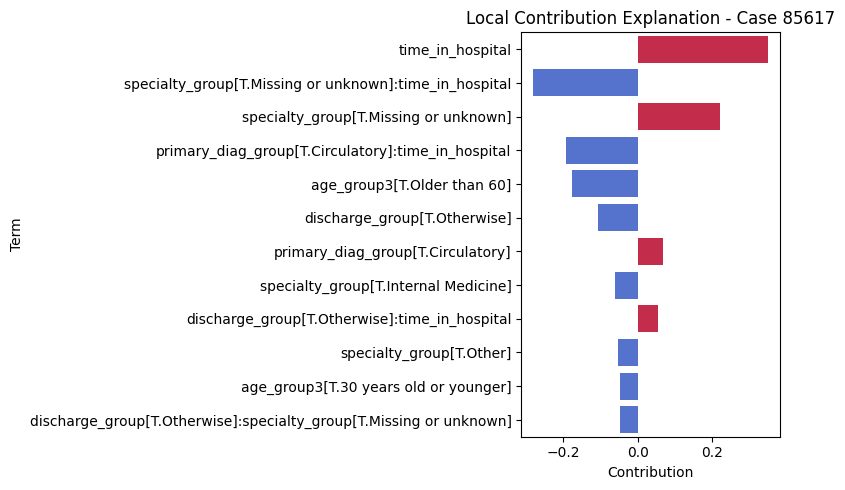

In [19]:
# -----------------------------
# 7. Exact local term contributions
# -----------------------------
def make_local_contrib_df(case_idx):
    row_design = X_design.loc[case_idx]
    row_centered = centered_contrib.loc[case_idx].drop("Intercept", errors="ignore")
    row_sorted = row_centered.reindex(row_centered.abs().sort_values(ascending=False).index)

    out = pd.DataFrame({
        "Term": row_sorted.index,
        "Contribution": row_sorted.values
    })
    return out

for idx in rep_cases.index:
    local_df = make_local_contrib_df(idx).head(12)

    print(f"\nLocal explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "readmitted_bin", "y_pred", "y_prob"]])

    plt.figure(figsize=(8, 5))
    colors = ["crimson" if x > 0 else "royalblue" for x in local_df["Contribution"]]


    local_df = local_df.copy()
    local_df["ColorGroup"] = np.where(local_df["Contribution"] > 0, "Positive", "Negative")

    sns.barplot(
        data=local_df,
        x="Contribution",
        y="Term",
        hue="ColorGroup",
        dodge=False,
        palette={"Positive": "crimson", "Negative": "royalblue"},
        legend=False
    )

    plt.title(f"Local Contribution Explanation - Case {idx}")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"hba1c_local_contrib_case_{idx}.png"), dpi=300)
    plt.show()


C:\Users\catia\AppData\Local\Temp\ipykernel_17460\321438170.py:35: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  .groupby(group_map_s, axis=1).sum()
C:\Users\catia\AppData\Local\Temp\ipykernel_17460\321438170.py:35: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  .groupby(group_map_s, axis=1).sum()
C:\Users\catia\AppData\Local\Temp\ipykernel_17460\321438170.py:35: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  .groupby(group_map_s, axis=1).sum()
c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\catia\AppData\Local\Temp\ipykernel_17460\321438170.py:35: FutureWarning: DataFrame.groupby with a


Stability summary
                                       MeanImportance  StdImportance  \
PredictorGroup                                                         
specialty_group                                0.4448         0.0672   
specialty_group × time_in_hospital             0.3099         0.0681   
time_in_hospital                               0.2964         0.0185   
primary_diag_group                             0.2817         0.0149   
primary_diag_group × time_in_hospital          0.2581         0.0261   
specialty_group × age_group3                   0.1963         0.0736   
discharge_group × specialty_group              0.1782         0.0407   
age_group3                                     0.1861         0.0600   
discharge_group                                0.1369         0.0452   
discharge_group × primary_diag_group           0.1039         0.0059   
hba1c_group                                    0.0862         0.0053   
primary_diag_group × hba1c_group             

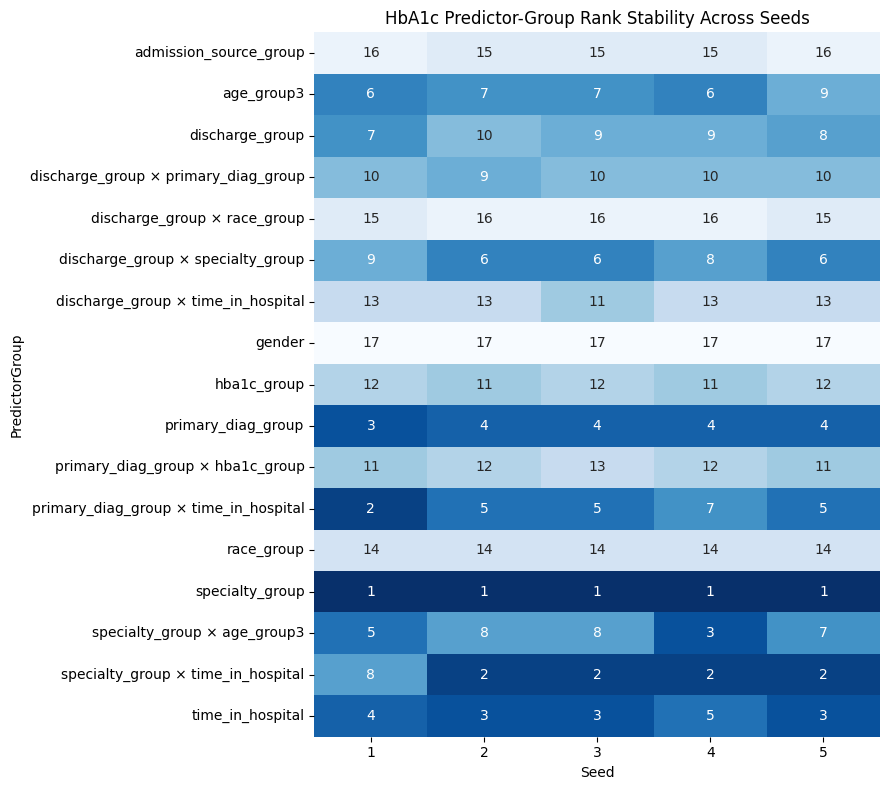

In [16]:
# -----------------------------
# 8. Stability analysis across seeds
# -----------------------------
import statsmodels.formula.api as smf

formula = final_model.model.formula

seeds = [1, 2, 3, 4, 5]
stability_rows = []

for seed in seeds:
    df_sub = analysis_df.sample(frac=0.8, random_state=seed).copy()

    model_s = smf.logit(formula, data=df_sub).fit(disp=0, maxiter=200)

    X_sub = build_design_matrices(
        [model_s.model.data.design_info],
        df_sub,
        return_type="dataframe"
    )[0]

    params_s = model_s.params.reindex(X_sub.columns)
    mean_x_s = X_sub.mean(axis=0)
    centered_s = (X_sub - mean_x_s).mul(params_s, axis=1)

    group_map_s = {
        col: base_from_term(col)
        for col in centered_s.columns
        if col != "Intercept"
    }

    group_imp_s = (
        centered_s.drop(columns=["Intercept"], errors="ignore")
        .abs()
        .groupby(group_map_s, axis=1).sum()
        .mean(axis=0)
        .reset_index()
    )
    group_imp_s.columns = ["PredictorGroup", "Importance"]
    group_imp_s["Seed"] = seed

    stability_rows.append(group_imp_s)

stability_df = pd.concat(stability_rows, ignore_index=True)

stability_df["Rank"] = stability_df.groupby("Seed")["Importance"].rank(
    ascending=False,
    method="min"
)

stability_summary = stability_df.groupby("PredictorGroup").agg(
    MeanImportance=("Importance", "mean"),
    StdImportance=("Importance", "std"),
    MeanRank=("Rank", "mean"),
    StdRank=("Rank", "std")
).sort_values("MeanRank")

print("\nStability summary")
print(stability_summary.round(4))

rank_pivot = stability_df.pivot(index="PredictorGroup", columns="Seed", values="Rank")
print("\nPredictor-group rank by seed")
print(rank_pivot)

plt.figure(figsize=(9, 8))
sns.heatmap(rank_pivot, annot=True, cmap="Blues_r", cbar=False)
plt.title("HbA1c Predictor-Group Rank Stability Across Seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "hba1c_rank_stability_heatmap.png"), dpi=300)
plt.show()


In [17]:
# -----------------------------
# 9. Final summary table
# -----------------------------
stability_export = stability_summary.reset_index()[[
    "PredictorGroup", "MeanImportance", "MeanRank", "StdRank"
]]

final_xai_summary = main_group_rank.merge(
    perm_rank,
    left_on="PredictorGroup",
    right_on="Feature",
    how="left"
).merge(
    stability_export,
    on="PredictorGroup",
    how="left"
).sort_values("GroupRank")

print(final_xai_summary.round(4))

term_importance.to_csv(os.path.join(out_dir, "hba1c_term_importance.csv"), index=False)
group_importance.to_csv(os.path.join(out_dir, "hba1c_group_importance.csv"), index=False)
perm_df.to_csv(os.path.join(out_dir, "hba1c_permutation_importance.csv"), index=False)
rank_compare.to_csv(os.path.join(out_dir, "hba1c_rank_compare.csv"), index=False)
stability_df.to_csv(os.path.join(out_dir, "hba1c_stability_raw.csv"), index=False)
stability_summary.to_csv(os.path.join(out_dir, "hba1c_stability_summary.csv"))
final_xai_summary.to_csv(os.path.join(out_dir, "hba1c_xai_final_summary.csv"), index=False)

print(f"\nAll HbA1c XAI outputs saved to: {out_dir}")


           PredictorGroup  MeanAbsContribution  GroupRank  \
0         specialty_group               0.4983          1   
1        time_in_hospital               0.2948          3   
2      primary_diag_group               0.2536          4   
3              age_group3               0.2136          6   
4         discharge_group               0.1340          9   
5             hba1c_group               0.0771         12   
6              race_group               0.0471         14   
7  admission_source_group               0.0393         15   
8                  gender               0.0141         17   

                  Feature  PermutationMean  PermutationStd  PermutationRank  \
0         specialty_group           0.0109          0.0009                4   
1        time_in_hospital           0.0148          0.0012                3   
2      primary_diag_group           0.0190          0.0017                2   
3              age_group3           0.0085          0.0009               